In [39]:
# ==============================
# Cell 1: Setup & Config (FIXED)
# ==============================
import os, gc, math, json, random, pathlib, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

# Paths (Sesuaikan jika perlu)
try:
    DATA_DIR = Path("/kaggle/input/intelecta-cup-data-mining-competition")
    if not DATA_DIR.exists(): DATA_DIR = Path(".")
except: DATA_DIR = Path(".")

TRAIN_PATH = DATA_DIR / "train.csv"
TEST_PATH  = DATA_DIR / "test.csv"
SUB_PATH   = DATA_DIR / "sample_submission.csv"

# Parameters
TARGET = "Suhu_Rata_Rata_C"
ID_COL = "ID"
SEED   = 42
EPS    = 0.5 # epsilon untuk stabilized MAPE (evaluasi)
EPS_WEIGHT = 1.0  # Konstanta minimum untuk denominator sample weight (PENTING!)

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)

set_seed(SEED)
print("Configured. Using data from:", DATA_DIR.resolve())

SMALL_VALUE_THRESHOLD = 1.0

Configured. Using data from: /kaggle/input/intelecta-cup-data-mining-competition


In [40]:
# ==============================
# Cell 2: Load Data
# ==============================
try:
    train = pd.read_csv(TRAIN_PATH)
    test  = pd.read_csv(TEST_PATH)
    sub   = pd.read_csv(SUB_PATH)
except FileNotFoundError:
    print("Error: Data files not found. Check DATA_DIR path.")
    raise

train['is_train'] = 1
test['is_train'] = 0
all_df = pd.concat([train, test], ignore_index=True)
all_df = all_df.sort_values(by=ID_COL).reset_index(drop=True)

print("train:", train.shape, "| test:", test.shape, "| all_df:", all_df.shape)

train: (8000, 16) | test: (2000, 15) | all_df: (10000, 16)


Target zero count: 0
Target negative count: 971


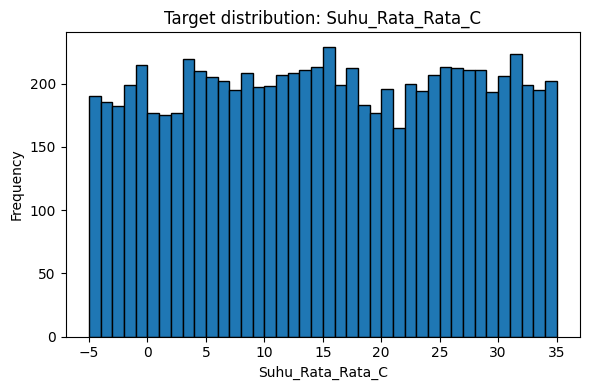

In [41]:
# ==============================
# Cell 3: Quick Target & Columns Check
# ==============================
assert TARGET in train.columns, f"Target '{TARGET}' not found in train."
print("Target zero count:", (train[TARGET]==0).sum())
print("Target negative count:", (train[TARGET]<0).sum())

plt.figure(figsize=(6,4))
train[TARGET].plot(kind="hist", bins=40, edgecolor="black")
plt.title(f"Target distribution: {TARGET}")
plt.xlabel(TARGET); plt.ylabel("Frequency")
plt.tight_layout(); plt.show()

In [42]:
# ==============================
# Cell 4: Utility - MAPE with epsilon (untuk EVALUASI)
# ==============================
from sklearn.metrics import make_scorer

def mape_eps(y_true, y_pred, eps=EPS):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    denom = np.maximum(np.abs(y_true), eps)
    denom = np.where(denom == 0, eps, denom)
    return np.mean(np.abs(y_true - y_pred) / denom) * 100.0

print("Test mape_eps:", mape_eps([1,2,3],[1,2,4]))

Test mape_eps: 11.11111111111111


In [43]:
# ==============================
# Cell 5: Basic Dtypes & Column Lists
# ==============================
cat_cols = all_df.select_dtypes(include="object").columns.tolist()
num_cols = [c for c in all_df.columns if c not in [TARGET, ID_COL, 'is_train'] and c not in cat_cols]

print("Categorical columns:", cat_cols)
print("Numeric columns:", num_cols)

Categorical columns: ['Nama_Negara', 'Wilayah', 'Jenis_Tanaman', 'Strategi_Adaptasi']
Numeric columns: ['Tahun', 'Total_Curah_Hujan_mm', 'Emisi_CO2_JT_Ton', 'Hasil_Panen_Ton_per_HA', 'Kejadian_Cuaca_Ekstrim', 'Akses_Irigasi', 'Penggunaan_Pestisida_KG_per_HA', 'Penggunaan_Pupuk_KG_per_HA', 'Indeks_Kesehatan_Tanah']


In [44]:
# ==============================
# Cell 6: Imputation (median per Wilayah)
# ==============================
GROUP_COL = "Wilayah"
print(f"Starting imputation based on group: {GROUP_COL}")

for c in cat_cols:
    all_df[c] = all_df[c].fillna("UNK")

num_cols_impute = [c for c in num_cols if c != 'Tahun']

df_train_only = all_df[all_df['is_train'] == 1]
med_map = df_train_only.groupby(GROUP_COL)[num_cols_impute].median()
global_medians = df_train_only[num_cols_impute].median()

for c in num_cols_impute:
    all_df[c] = all_df[c].fillna(all_df[GROUP_COL].map(med_map[c]))
    all_df[c] = all_df[c].fillna(global_medians[c])

print("Imputation done. NaN counts in all_df:", all_df.isna().sum().sum())

Starting imputation based on group: Wilayah
Imputation done. NaN counts in all_df: 2000


In [45]:
# ==============================
# Cell 7: Winsorize per group
# ==============================
def winsorize_per_group(df, cols, group_col=None, p_low=0.02, p_high=0.98):
    df_out = df.copy()
    if not cols: return df_out

    print(f"Winsorizing based on group: {group_col}")
    df_train_only = df[df['is_train']==1]

    for c in cols:
        s_lo = df_train_only.groupby(group_col)[c].quantile(p_low)
        s_hi = df_train_only.groupby(group_col)[c].quantile(p_high)
        glo = df_train_only[c].quantile(p_low)
        ghi = df_train_only[c].quantile(p_high)

        lo = df_out[group_col].map(s_lo).fillna(glo)
        hi = df_out[group_col].map(s_hi).fillna(ghi)

        df_out[c] = np.clip(df_out[c].values, lo.values, hi.values)
    return df_out

num_cols_winsorize = [c for c in num_cols if c != 'Tahun']
all_df = winsorize_per_group(all_df, num_cols_winsorize, GROUP_COL, 0.02, 0.98)

print("Winsorizing done.")

Winsorizing based on group: Wilayah
Winsorizing done.


In [46]:
# ==============================
# Cell A1: Transform & cap hasil panen
# ==============================
PANEN = "Hasil_Panen_Ton_per_HA"
if PANEN in all_df.columns:
    print(f"Transforming '{PANEN}'...")

    df_train_only = all_df[all_df['is_train']==1]
    q1 = df_train_only.groupby(GROUP_COL)[PANEN].quantile(0.01)
    q9 = df_train_only.groupby(GROUP_COL)[PANEN].quantile(0.99)
    glo1 = df_train_only[PANEN].quantile(0.01)
    ghi9 = df_train_only[PANEN].quantile(0.99)

    lo = all_df[GROUP_COL].map(q1).fillna(glo1)
    hi = all_df[GROUP_COL].map(q9).fillna(ghi9)
    all_df[PANEN] = np.clip(all_df[PANEN].values, lo.values, hi.values)

    shift = max(1e-6, float((df_train_only[PANEN].min() <= 0)) * (abs(df_train_only[PANEN].min()) + 1e-3))
    all_df[PANEN+"_log"] = np.log1p(all_df[PANEN] + shift)

    if PANEN in num_cols: num_cols.remove(PANEN)
    if PANEN+"_log" not in num_cols: num_cols.append(PANEN+"_log")
    all_df.drop(columns=[PANEN], errors="ignore", inplace=True)

    print("Panen transformed (log) and capped.")
else:
    print(f"Column '{PANEN}' not found.")

Transforming 'Hasil_Panen_Ton_per_HA'...
Panen transformed (log) and capped.


In [47]:
# ==============================
# Cell 8: Advanced Feature Engineering (RASIO, LAGS, PEMBERSIHAN)
# ==============================
print("Membuat Fitur Rasio, Lag, dan Geo...")
panen_col = PANEN+"_log" if PANEN+"_log" in all_df.columns else PANEN

# --- 1. Fitur Rasio & Interaksi ---
safe_div = lambda a, b: a / (b + 1e-6)
all_df["Curah_per_CO2"] = safe_div(all_df["Total_Curah_Hujan_mm"], all_df["Emisi_CO2_JT_Ton"])
all_df["Pupuk_per_Pestisida"] = safe_div(all_df["Penggunaan_Pupuk_KG_per_HA"], all_df["Penggunaan_Pestisida_KG_per_HA"])
if panen_col in all_df.columns:
    all_df["Hasil_per_Curah"] = safe_div(all_df[panen_col], all_df["Total_Curah_Hujan_mm"])
else: print(f"Warning: Column '{panen_col}' not found for 'Hasil_per_Curah'.")
all_df["Irigasi_x_Hujan"] = all_df["Akses_Irigasi"] * all_df["Total_Curah_Hujan_mm"]

# --- 2. Fitur Geo-Temporal ---
zona_map = {'Russia': 3, 'Canada': 3, 'USA': 2, 'China': 2, 'France': 2, 'India': 1, 'Nigeria': -1, 'Brazil': -1, 'Argentina': -2, 'Australia': -2}
all_df['Zona_Iklim'] = all_df['Nama_Negara'].map(zona_map).fillna(0)
all_df["Tahun_sq"] = (all_df["Tahun"] - 1990)**2

# --- 3. Interaksi Kategori ---
all_df['Negara_Wilayah'] = all_df['Nama_Negara'].astype(str) + '_' + all_df['Wilayah'].astype(str)
if 'Negara_Wilayah' not in cat_cols:
    cat_cols.append('Negara_Wilayah')

# --- 4. Lag Features (Time Series) ---
all_df = all_df.sort_values(by=['Wilayah', 'Tahun'])
lag_cols = ['Total_Curah_Hujan_mm', 'Emisi_CO2_JT_Ton', panen_col, 'Penggunaan_Pupuk_KG_per_HA']
created_lag_cols = []
for col in lag_cols:
    if col in all_df.columns:
        lag_col_name = f'Lag_1_{col}'
        all_df[lag_col_name] = all_df.groupby('Wilayah')[col].shift(1)
        med_lag = all_df[all_df['is_train']==1].groupby('Wilayah')[lag_col_name].median()
        all_df[lag_col_name] = all_df[lag_col_name].fillna(all_df['Wilayah'].map(med_lag))
        all_df[lag_col_name] = all_df[lag_col_name].fillna(0)
        created_lag_cols.append(lag_col_name)
    else: print(f"Warning: Column '{col}' not found for lag feature creation.")

all_df = all_df.sort_index()

# --- 5. (KRUSIAL) Pembersihan Fitur Baru ---
print("Membersihkan inf dan NaN dari fitur baru...")
new_num_cols = [
    'Curah_per_CO2', 'Pupuk_per_Pestisida', 'Hasil_per_Curah', 'Irigasi_x_Hujan',
    'Tahun_sq', 'Zona_Iklim'
] + created_lag_cols

for col in new_num_cols:
    if col in all_df.columns:
        all_df[col] = all_df[col].replace([np.inf, -np.inf], np.nan)
        all_df[col] = all_df[col].fillna(0)

print("Feature engineering (Rasio, Lag) complete.")

Membuat Fitur Rasio, Lag, dan Geo...
Membersihkan inf dan NaN dari fitur baru...
Feature engineering (Rasio, Lag) complete.


In [48]:
# ==============================
# Cell 8b: Aggregate Features (FIXED)
# ==============================
print("Membuat Fitur Agregat...")

agg_group_cols = ['Wilayah', 'Nama_Negara', 'Jenis_Tanaman', 'Strategi_Adaptasi']
agg_num_cols = ['Total_Curah_Hujan_mm', 'Emisi_CO2_JT_Ton', 'Penggunaan_Pupuk_KG_per_HA', 'Indeks_Kesehatan_Tanah']

df_train_only = all_df[all_df['is_train']==1].copy()
added_agg_features = []

for group_col in agg_group_cols:
    for num_col in agg_num_cols:
        if group_col in df_train_only.columns and num_col in df_train_only.columns:
            print(f"  Menghitung agregat untuk {group_col} / {num_col}...")
            mean_col = f'Agg_{group_col}_{num_col}_mean'
            std_col = f'Agg_{group_col}_{num_col}_std'
            stats = df_train_only.groupby(group_col)[num_col].agg(['mean', 'std']).reset_index()
            stats.columns = [group_col, mean_col, std_col]
            all_df = pd.merge(all_df, stats, on=group_col, how='left')
            added_agg_features.extend([mean_col, std_col])
        else: print(f"Warning: Columns '{group_col}' or '{num_col}' not found.")

all_df[added_agg_features] = all_df[added_agg_features].fillna(0)

print(f"Fitur Agregat selesai. Menambahkan {len(added_agg_features)} fitur baru.")

Membuat Fitur Agregat...
  Menghitung agregat untuk Wilayah / Total_Curah_Hujan_mm...
  Menghitung agregat untuk Wilayah / Emisi_CO2_JT_Ton...
  Menghitung agregat untuk Wilayah / Penggunaan_Pupuk_KG_per_HA...
  Menghitung agregat untuk Wilayah / Indeks_Kesehatan_Tanah...
  Menghitung agregat untuk Nama_Negara / Total_Curah_Hujan_mm...
  Menghitung agregat untuk Nama_Negara / Emisi_CO2_JT_Ton...
  Menghitung agregat untuk Nama_Negara / Penggunaan_Pupuk_KG_per_HA...
  Menghitung agregat untuk Nama_Negara / Indeks_Kesehatan_Tanah...
  Menghitung agregat untuk Jenis_Tanaman / Total_Curah_Hujan_mm...
  Menghitung agregat untuk Jenis_Tanaman / Emisi_CO2_JT_Ton...
  Menghitung agregat untuk Jenis_Tanaman / Penggunaan_Pupuk_KG_per_HA...
  Menghitung agregat untuk Jenis_Tanaman / Indeks_Kesehatan_Tanah...
  Menghitung agregat untuk Strategi_Adaptasi / Total_Curah_Hujan_mm...
  Menghitung agregat untuk Strategi_Adaptasi / Emisi_CO2_JT_Ton...
  Menghitung agregat untuk Strategi_Adaptasi / Penggu

In [49]:
# ==============================
# Cell 9: Prepare features (Dengan PowerTransformer + FEATURE SELECTION)
# ==============================
from sklearn.preprocessing import PowerTransformer
from sklearn.preprocessing import StandardScaler

# Pisahkan kembali train dan test
train = all_df[all_df['is_train']==1].drop(columns=['is_train'])
test = all_df[all_df['is_train']==0].drop(columns=['is_train', TARGET])

# Ambil SEMUA kolom potensial dulu
ALL_POTENTIAL_FEATURES = [c for c in train.columns if c not in [TARGET, ID_COL]]

# --- (BARU) FEATURE SELECTION: Hapus turunan Hasil Panen ---
# Tentukan nama kolom hasil panen (log)
panen_col_log = PANEN + "_log" if PANEN + "_log" in ALL_POTENTIAL_FEATURES else None

features_to_drop = []
if panen_col_log:
    print(f"Mengidentifikasi fitur turunan dari '{panen_col_log}' untuk dihapus...")
    # Cari fitur Lag, Agregat, atau Rasio yang menggunakan panen_col_log
    for feature in ALL_POTENTIAL_FEATURES:
        if feature == panen_col_log: # Jangan hapus fitur aslinya
            continue
        # Cek nama fitur (mungkin perlu disesuaikan jika nama berbeda)
        if panen_col_log in feature or "Hasil_per_Curah" in feature: # Cek Rasio juga
             # Cek nama fitur agregat (contoh)
             if feature.startswith("Agg_") and panen_col_log in feature:
                  features_to_drop.append(feature)
             # Cek nama fitur lag (contoh)
             elif feature.startswith("Lag_") and panen_col_log in feature:
                  features_to_drop.append(feature)
             # Cek nama fitur rasio (contoh)
             elif "Hasil_per_Curah" in feature: # Asumsi ini satu2nya rasio dg panen
                  features_to_drop.append(feature)

    print(f"Fitur turunan hasil panen yang akan dihapus ({len(features_to_drop)}): {features_to_drop}")
else:
    print("Kolom hasil panen (log) tidak ditemukan, tidak ada fitur turunan yang dihapus.")

# Buat list FEATURES final setelah menghapus
FEATURES = [f for f in ALL_POTENTIAL_FEATURES if f not in features_to_drop]
print(f"Jumlah fitur setelah seleksi: {len(FEATURES)}")
# ----------------------------------------------------

X = train[FEATURES].copy()
y = train[TARGET].values # y ASLI
# Pastikan X_test hanya punya kolom FEATURES
X_test = test[FEATURES].copy()

# Cleaning y asli
y = pd.Series(y, index=X.index).fillna(0).values
print(f"Membersihkan y (asli). Jumlah NaN di y: {np.isnan(y).sum()}")

# --- POWER TRANSFORMER (Yeo-Johnson) ---
numeric_features_all = X.select_dtypes(include=np.number).columns.tolist()
if 'Tahun' in numeric_features_all: numeric_features_all.remove('Tahun')

numeric_features_existing = [col for col in numeric_features_all if col in X.columns]
print(f"\nKolom numerik yang akan di-transform Power ({len(numeric_features_existing)}): {numeric_features_existing}")

pt = PowerTransformer(method='yeo-johnson', standardize=True)
constant_cols = []
numeric_features_transformable = numeric_features_existing[:]

try:
    if numeric_features_transformable: # Pastikan tidak kosong
        X[numeric_features_transformable] = pt.fit_transform(X[numeric_features_transformable])
except ValueError as e:
    print(f"ValueError during fit_transform: {e}. Checking for constant columns.")
    constant_cols = X[numeric_features_existing].loc[:, X[numeric_features_existing].std() == 0].columns.tolist()
    if constant_cols:
        print(f"Found constant columns: {constant_cols}. Excluding them.")
        numeric_features_transformable = [col for col in numeric_features_existing if col not in constant_cols]
        if numeric_features_transformable:
             X[numeric_features_transformable] = pt.fit_transform(X[numeric_features_transformable])
        for col in constant_cols:
            if col in X.columns: X[col] = 0
    else: raise e

if numeric_features_transformable:
    try:
        # Transform test set hanya pada kolom yg di-fit
        X_test[numeric_features_transformable] = pt.transform(X_test[numeric_features_transformable])
    except ValueError as e:
        print(f"ValueError during transform on test set: {e}. Check test data.")
        X_test[numeric_features_transformable] = np.nan

for col in constant_cols:
     if col in X_test.columns: X_test[col] = 0

print("Fitur numerik telah di-transformasi.")
# ------------------------------------

cat_cols_final = X.select_dtypes(include=["object", "category"]).columns.tolist()
for c in cat_cols_final:
    if c in X.columns: X[c] = X[c].astype(str)
    if c in X_test.columns: X_test[c] = X_test[c].astype(str)

print("\nn_features:", len(FEATURES))
print("Final Categorical columns:", cat_cols_final)
print("X shape:", X.shape, "| X_test shape:", X_test.shape)

# Penyelarasan kolom X_test (penting setelah feature selection)
missing_cols = set(X.columns) - set(X_test.columns)
for c in missing_cols: X_test[c] = 0
added_cols = set(X_test.columns) - set(X.columns)
if added_cols: X_test = X_test.drop(columns=list(added_cols))
X_test = X_test[X.columns]
print("X_test shape after column alignment:", X_test.shape)

Mengidentifikasi fitur turunan dari 'Hasil_Panen_Ton_per_HA_log' untuk dihapus...
Fitur turunan hasil panen yang akan dihapus (2): ['Hasil_per_Curah', 'Lag_1_Hasil_Panen_Ton_per_HA_log']
Jumlah fitur setelah seleksi: 54
Membersihkan y (asli). Jumlah NaN di y: 0

Kolom numerik yang akan di-transform Power (48): ['Total_Curah_Hujan_mm', 'Emisi_CO2_JT_Ton', 'Kejadian_Cuaca_Ekstrim', 'Akses_Irigasi', 'Penggunaan_Pestisida_KG_per_HA', 'Penggunaan_Pupuk_KG_per_HA', 'Indeks_Kesehatan_Tanah', 'Hasil_Panen_Ton_per_HA_log', 'Curah_per_CO2', 'Pupuk_per_Pestisida', 'Irigasi_x_Hujan', 'Zona_Iklim', 'Tahun_sq', 'Lag_1_Total_Curah_Hujan_mm', 'Lag_1_Emisi_CO2_JT_Ton', 'Lag_1_Penggunaan_Pupuk_KG_per_HA', 'Agg_Wilayah_Total_Curah_Hujan_mm_mean', 'Agg_Wilayah_Total_Curah_Hujan_mm_std', 'Agg_Wilayah_Emisi_CO2_JT_Ton_mean', 'Agg_Wilayah_Emisi_CO2_JT_Ton_std', 'Agg_Wilayah_Penggunaan_Pupuk_KG_per_HA_mean', 'Agg_Wilayah_Penggunaan_Pupuk_KG_per_HA_std', 'Agg_Wilayah_Indeks_Kesehatan_Tanah_mean', 'Agg_Wilayah_

In [50]:
# ==============================
# Cell B1: Sample weight for MAPE alignment (AKTIF)
# ==============================
w = 1.0 / np.maximum(np.abs(y), EPS_WEIGHT) # y diambil dari Cell 9 (asli)

# Perbaikan NaN
w = pd.Series(w).fillna(1.0).values
print(f"Membersihkan w. Jumlah NaN di w: {np.isnan(w).sum()}")

print("Sample weight stats:", float(np.min(w)), float(np.median(w)), float(np.max(w)))

Membersihkan w. Jumlah NaN di w: 0
Sample weight stats: 0.02857142857142857 0.06605019815059444 1.0


In [51]:
# ==============================
# Cell 10: CV Split (GroupKFold by Tahun)
# ==============================
from sklearn.model_selection import GroupKFold
groups = train["Tahun"].values if "Tahun" in train.columns else None
n_splits = 5
gkf = GroupKFold(n_splits=n_splits) if groups is not None else None
print("Use GroupKFold by Tahun:", gkf is not None)

Use GroupKFold by Tahun: True


In [52]:
# ==============================
# Cell 11: Latih Model Utama (CatBoost Huber + Weight + PowerTransform + Reg Kuat)
# ==============================
from catboost import CatBoostRegressor, Pool
from sklearn.model_selection import GroupKFold

print("\n--- Melatih Model Utama: CatBoost ---") # Label diubah
cat_idx = [X.columns.get_loc(c) for c in cat_cols_final if c in X.columns]
print(f"CatBoost categorical feature indices: {cat_idx}")

# Ganti nama variabel untuk menyimpan hasil Model Utama
oof_preds_main = np.zeros(len(train))
test_preds_main = np.zeros(len(test))
models_main = [] # Simpan model utama

gkf_main = GroupKFold(n_splits=n_splits)
for fold, (train_idx, valid_idx) in enumerate(gkf_main.split(X, y, groups=groups)):
    print(f"--- Main Model Fold {fold+1}/{n_splits} ---") # Label diubah
    X_train, y_train_fold = X.iloc[train_idx], y[train_idx]
    X_valid, y_valid_fold = X.iloc[valid_idx], y[valid_idx]

    w_train = w[train_idx]
    w_valid = w[valid_idx]

    train_pool = Pool(data=X_train, label=y_train_fold, cat_features=cat_idx, weight=w_train)
    valid_pool = Pool(data=X_valid, label=y_valid_fold, cat_features=cat_idx, weight=w_valid)

    huber_delta = 1.0

    # Gunakan parameter terbaikmu yang menghasilkan OOF ~84
    model_main = CatBoostRegressor(
        n_estimators=10000,
        learning_rate=0.02,
        depth=6,
        early_stopping_rounds=300,
        loss_function=f'Huber:delta={huber_delta}',
        eval_metric='MAE',
        l2_leaf_reg=30.0, # Regulasi kuat
        colsample_bylevel=0.7, # Regulasi kuat
        random_seed=SEED,
        verbose=500,
    )

    model_main.fit(train_pool, eval_set=valid_pool, verbose=500)

    val_preds = model_main.predict(X_valid)
    oof_preds_main[valid_idx] = val_preds # Simpan ke var utama

    current_test_preds = model_main.predict(X_test)
    if fold == 0 or test_preds_main.shape != current_test_preds.shape:
         test_preds_main = np.zeros_like(current_test_preds)
    test_preds_main += current_test_preds / n_splits # Simpan ke var utama

    models_main.append(model_main) # Simpan model utama

    fold_score = mape_eps(y_valid_fold, val_preds, eps=EPS)
    print(f"Main Model Fold {fold+1} Stabilized MAPE (eval): {fold_score:.4f}") # Label diubah

print("\nMain Model training complete.")
oof_score_main = mape_eps(y, oof_preds_main, eps=EPS)
print(f"Overall OOF Stabilized MAPE (Main Model): {oof_score_main:.4f}") # Label diubah

# Simpan oof_preds dan test_preds utama ke variabel utama sementara
# Ini akan ditimpa oleh hasil two-stage di Cell 13
oof_preds = oof_preds_main.copy()
test_preds = test_preds_main.copy()
models = models_main # Simpan model utama ke var utama


--- Melatih Model Utama: CatBoost ---
CatBoost categorical feature indices: [1, 2, 3, 11, 18]
--- Main Model Fold 1/5 ---
0:	learn: 5.5799763	test: 5.6501910	best: 5.6501910 (0)	total: 18.6ms	remaining: 3m 5s
500:	learn: 4.4379043	test: 4.5293139	best: 4.5293139 (500)	total: 4.17s	remaining: 1m 19s
1000:	learn: 4.2506652	test: 4.4911156	best: 4.4909236 (982)	total: 8.29s	remaining: 1m 14s
1500:	learn: 4.1014895	test: 4.4667907	best: 4.4664942 (1495)	total: 12.5s	remaining: 1m 10s
2000:	learn: 3.9801989	test: 4.4525235	best: 4.4522627 (1996)	total: 16.8s	remaining: 1m 7s
2500:	learn: 3.8859635	test: 4.4521285	best: 4.4499927 (2377)	total: 21s	remaining: 1m 2s
Stopped by overfitting detector  (300 iterations wait)

bestTest = 4.449992675
bestIteration = 2377

Shrink model to first 2378 iterations.
Main Model Fold 1 Stabilized MAPE (eval): 80.6930
--- Main Model Fold 2/5 ---
0:	learn: 5.6039701	test: 5.5550758	best: 5.5550758 (0)	total: 8.87ms	remaining: 1m 28s
500:	learn: 4.3827538	test

In [53]:
# ==============================
# Cell 11.5: (BARU) Latih Model Spesialis (Nilai Kecil)
# ==============================
from catboost import CatBoostRegressor, Pool
from sklearn.model_selection import GroupKFold
import numpy as np

print(f"\n--- Melatih Model Spesialis untuk abs(Target) < {SMALL_VALUE_THRESHOLD} ---")

# 1. Filter data training untuk nilai target kecil (gunakan y asli dari Cell 9)
train_small_idx = np.where(np.abs(y) < SMALL_VALUE_THRESHOLD)[0]

# Pastikan ada data yang memenuhi kriteria
if len(train_small_idx) > 0:
    X_small = X.iloc[train_small_idx].copy()
    y_small = y[train_small_idx].copy() # Target asli subset
    groups_small = groups[train_small_idx] if groups is not None else None
    w_small = w[train_small_idx].copy() # Bobot sample_weight subset

    print(f"Jumlah data training untuk model spesialis: {len(X_small)}")

    # 2. Latih CatBoost pada subset ini (KFold)
    oof_preds_small = np.zeros(len(y_small)) # OOF hanya untuk subset
    models_small = []
    gkf_small = GroupKFold(n_splits=n_splits)

    for fold, (train_s_idx, valid_s_idx) in enumerate(gkf_small.split(X_small, y_small, groups=groups_small)):
        print(f"--- Small Model Fold {fold+1}/{n_splits} ---")
        X_train_s, y_train_s = X_small.iloc[train_s_idx], y_small[train_s_idx]
        X_valid_s, y_valid_s = X_small.iloc[valid_s_idx], y_small[valid_s_idx]
        w_train_s, w_valid_s = w_small[train_s_idx], w_small[valid_s_idx]

        # Pastikan cat_idx valid untuk subset
        cat_idx_small = [X_small.columns.get_loc(c) for c in cat_cols_final if c in X_small.columns]

        train_pool_s = Pool(data=X_train_s, label=y_train_s, cat_features=cat_idx_small, weight=w_train_s)
        valid_pool_s = Pool(data=X_valid_s, label=y_valid_s, cat_features=cat_idx_small, weight=w_valid_s)

        # Coba parameter yang sama atau lebih simpel/regularized
        model_s = CatBoostRegressor(
            n_estimators=8000,
            learning_rate=0.02,
            depth=5, # Coba depth lebih kecil
            early_stopping_rounds=300,
            loss_function=f'Huber:delta=0.5', # Coba delta lebih kecil
            eval_metric='MAE',
            l2_leaf_reg=20.0,
            colsample_bylevel=0.8,
            random_seed=SEED + fold,
            verbose=1000,
        )

        model_s.fit(train_pool_s, eval_set=valid_pool_s, verbose=1000)

        val_preds_s = model_s.predict(X_valid_s)
        oof_preds_small[valid_s_idx] = val_preds_s
        models_small.append(model_s)

        fold_mape_s = mape_eps(y_valid_s, val_preds_s, eps=EPS)
        print(f"  Small Model Fold {fold+1} OOF MAPE (on subset): {fold_mape_s:.4f}")

    print("\nTraining Model Spesialis selesai.")
    oof_mape_small_overall = mape_eps(y_small, oof_preds_small, eps=EPS)
    print(f"Overall OOF MAPE Model Spesialis (on subset): {oof_mape_small_overall:.4f}")

    # Rata-ratakan prediksi test dari semua fold model spesialis
    test_preds_small_folds = np.zeros((len(test), n_splits))
    print("Membuat prediksi test dari model spesialis...")
    for i, model_s in enumerate(models_small):
         test_preds_small_folds[:, i] = model_s.predict(X_test)
    test_preds_small_avg = np.mean(test_preds_small_folds, axis=1)
    print("Prediksi test model spesialis selesai.")

else:
    print(f"Tidak ada data training yang memenuhi kriteria abs(Target) < {SMALL_VALUE_THRESHOLD}. Model spesialis tidak dilatih.")
    # Set prediksi spesialis ke array kosong atau handle sesuai kebutuhan
    test_preds_small_avg = np.array([])
    models_small = []


--- Melatih Model Spesialis untuk abs(Target) < 1.0 ---
Jumlah data training untuk model spesialis: 389
--- Small Model Fold 1/5 ---
0:	learn: 0.5039748	test: 0.5208065	best: 0.5208065 (0)	total: 4.35ms	remaining: 34.8s
Stopped by overfitting detector  (300 iterations wait)

bestTest = 0.5048983714
bestIteration = 274

Shrink model to first 275 iterations.
  Small Model Fold 1 OOF MAPE (on subset): 74.4350
--- Small Model Fold 2/5 ---
0:	learn: 0.4952082	test: 0.5572374	best: 0.5572374 (0)	total: 3.13ms	remaining: 25.1s
Stopped by overfitting detector  (300 iterations wait)

bestTest = 0.5572172913
bestIteration = 1

Shrink model to first 2 iterations.
  Small Model Fold 2 OOF MAPE (on subset): 79.7402
--- Small Model Fold 3/5 ---
0:	learn: 0.5143221	test: 0.4805735	best: 0.4805735 (0)	total: 3.21ms	remaining: 25.7s
Stopped by overfitting detector  (300 iterations wait)

bestTest = 0.4661204478
bestIteration = 458

Shrink model to first 459 iterations.
  Small Model Fold 3 OOF MAPE (o

In [54]:
# ==============================
# Cell 11.6: (BARU) Blending Adaptif dengan Prediksi Nol
# ==============================
import numpy as np
import pandas as pd # Pastikan pandas diimport jika belum

print("\n--- Blending Adaptif dengan Prediksi Nol ---")

# Pastikan oof_preds (dari CatBoost utama di Cell 11) dan y (asli) sudah ada
try:
    assert 'oof_preds' in locals() and 'y' in locals()
    oof_preds_main = oof_preds.copy() # Simpan prediksi utama
    # Pastikan test_preds (dari CatBoost utama di Cell 11) sudah ada
    assert 'test_preds' in locals()
    test_preds_main = test_preds.copy() # Simpan prediksi utama test
except (NameError, AssertionError) as e:
    print(f"Error: Variabel oof_preds/test_preds/y tidak ditemukan. Jalankan Cell 11 dulu. {e}")
    raise

# Buat prediksi aman (nol)
oof_preds_zero = np.zeros_like(y)
test_preds_zero = np.zeros(len(test_preds_main)) # Gunakan panjang test_preds_main

# --- Fungsi Bobot Adaptif ---
# Fungsi ini menghasilkan bobot untuk prediksi NOL (pred_B)
# Bobot mendekati 1 jika |prediksi utama| kecil, mendekati 0 jika besar
def calculate_zero_blend_weight(predictions, threshold=1.5, steepness=2.0):
    abs_pred = np.abs(predictions)
    # Sigmoid terbalik: weight = 1 / (1 + exp(steepness * (abs_pred - threshold)))
    weight = 1.0 / (1.0 + np.exp(steepness * (abs_pred - threshold)))
    # Pastikan bobot valid (antara 0 dan 1)
    weight = np.clip(weight, 0.0, 1.0)
    return weight

# --- Tuning Parameter Fungsi Bobot di OOF ---
best_oof_mape_adapt = float('inf')
best_params_adapt = {'threshold': 1.5, 'steepness': 2.0} # Nilai awal
oof_blend_adapt_best = oof_preds_main.copy() # Inisialisasi hasil blend terbaik

print("Mencari parameter blending adaptif terbaik (Threshold, Steepness)...")
# Coba range parameter (bisa diperluas atau pakai Optuna)
for t in [0.5, 0.75, 1.0, 1.25, 1.5, 2.0, 2.5]: # Threshold di sekitar EPS
    for s in [1.0, 1.5, 2.0, 2.5, 3.0, 4.0, 5.0]: # Tingkat "kekuatan" blending
        # Hitung bobot untuk prediksi nol (alpha_B) berdasarkan prediksi OOF utama
        alpha_B_oof = calculate_zero_blend_weight(oof_preds_main, threshold=t, steepness=s)
        # Bobot untuk prediksi utama (alpha_A)
        alpha_A_oof = 1.0 - alpha_B_oof

        # Buat prediksi OOF hasil blending
        oof_blend_adapt_current = alpha_A_oof * oof_preds_main + alpha_B_oof * oof_preds_zero

        # Evaluasi MAPE OOF hasil blending
        current_mape_adapt = mape_eps(y, oof_blend_adapt_current, eps=EPS)
        # print(f"  T={t:.2f}, S={s:.1f} -> OOF MAPE: {current_mape_adapt:.4f}") # Optional: print tiap iterasi

        # Update jika lebih baik
        if current_mape_adapt < best_oof_mape_adapt:
            best_oof_mape_adapt = current_mape_adapt
            best_params_adapt['threshold'] = t
            best_params_adapt['steepness'] = s
            oof_blend_adapt_best = oof_blend_adapt_current # Simpan hasil blend OOF terbaik

print(f"\nParameter Blending Adaptif Terbaik: {best_params_adapt}")
print(f"OOF MAPE Blend Adaptif Terbaik: {best_oof_mape_adapt:.4f}")

# --- Buat Prediksi Test Final dengan Blending Adaptif ---
print("\nMenerapkan blending adaptif ke prediksi test...")
# Hitung bobot untuk prediksi nol (alpha_B) berdasarkan prediksi TEST utama
alpha_B_test = calculate_zero_blend_weight(test_preds_main, **best_params_adapt)
# Bobot untuk prediksi utama (alpha_A)
alpha_A_test = 1.0 - alpha_B_test

# Buat prediksi test final hasil blending
test_preds_final_adapt = alpha_A_test * test_preds_main + alpha_B_test * test_preds_zero

# --- UPDATE VARIABEL PREDIKSI FINAL ---
# Timpa variabel oof_preds dan test_preds dengan hasil blending adaptif
oof_preds = oof_blend_adapt_best # Gunakan hasil blend OOF terbaik
test_preds = test_preds_final_adapt

print("Variabel 'oof_preds' dan 'test_preds' telah diupdate dengan hasil blending adaptif.")


--- Blending Adaptif dengan Prediksi Nol ---
Mencari parameter blending adaptif terbaik (Threshold, Steepness)...

Parameter Blending Adaptif Terbaik: {'threshold': 2.5, 'steepness': 1.0}
OOF MAPE Blend Adaptif Terbaik: 82.1347

Menerapkan blending adaptif ke prediksi test...
Variabel 'oof_preds' dan 'test_preds' telah diupdate dengan hasil blending adaptif.



Overall OOF Stabilized MAPE (Adaptive Blend): 82.1347


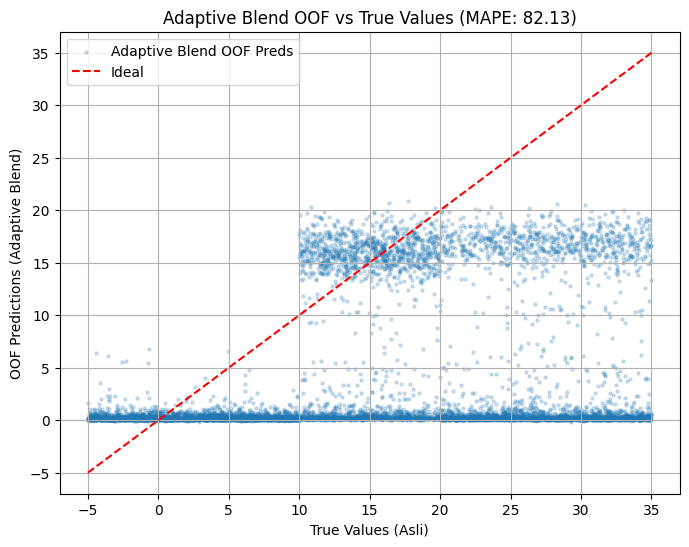


--- Feature Importance (dari Model Utama) ---


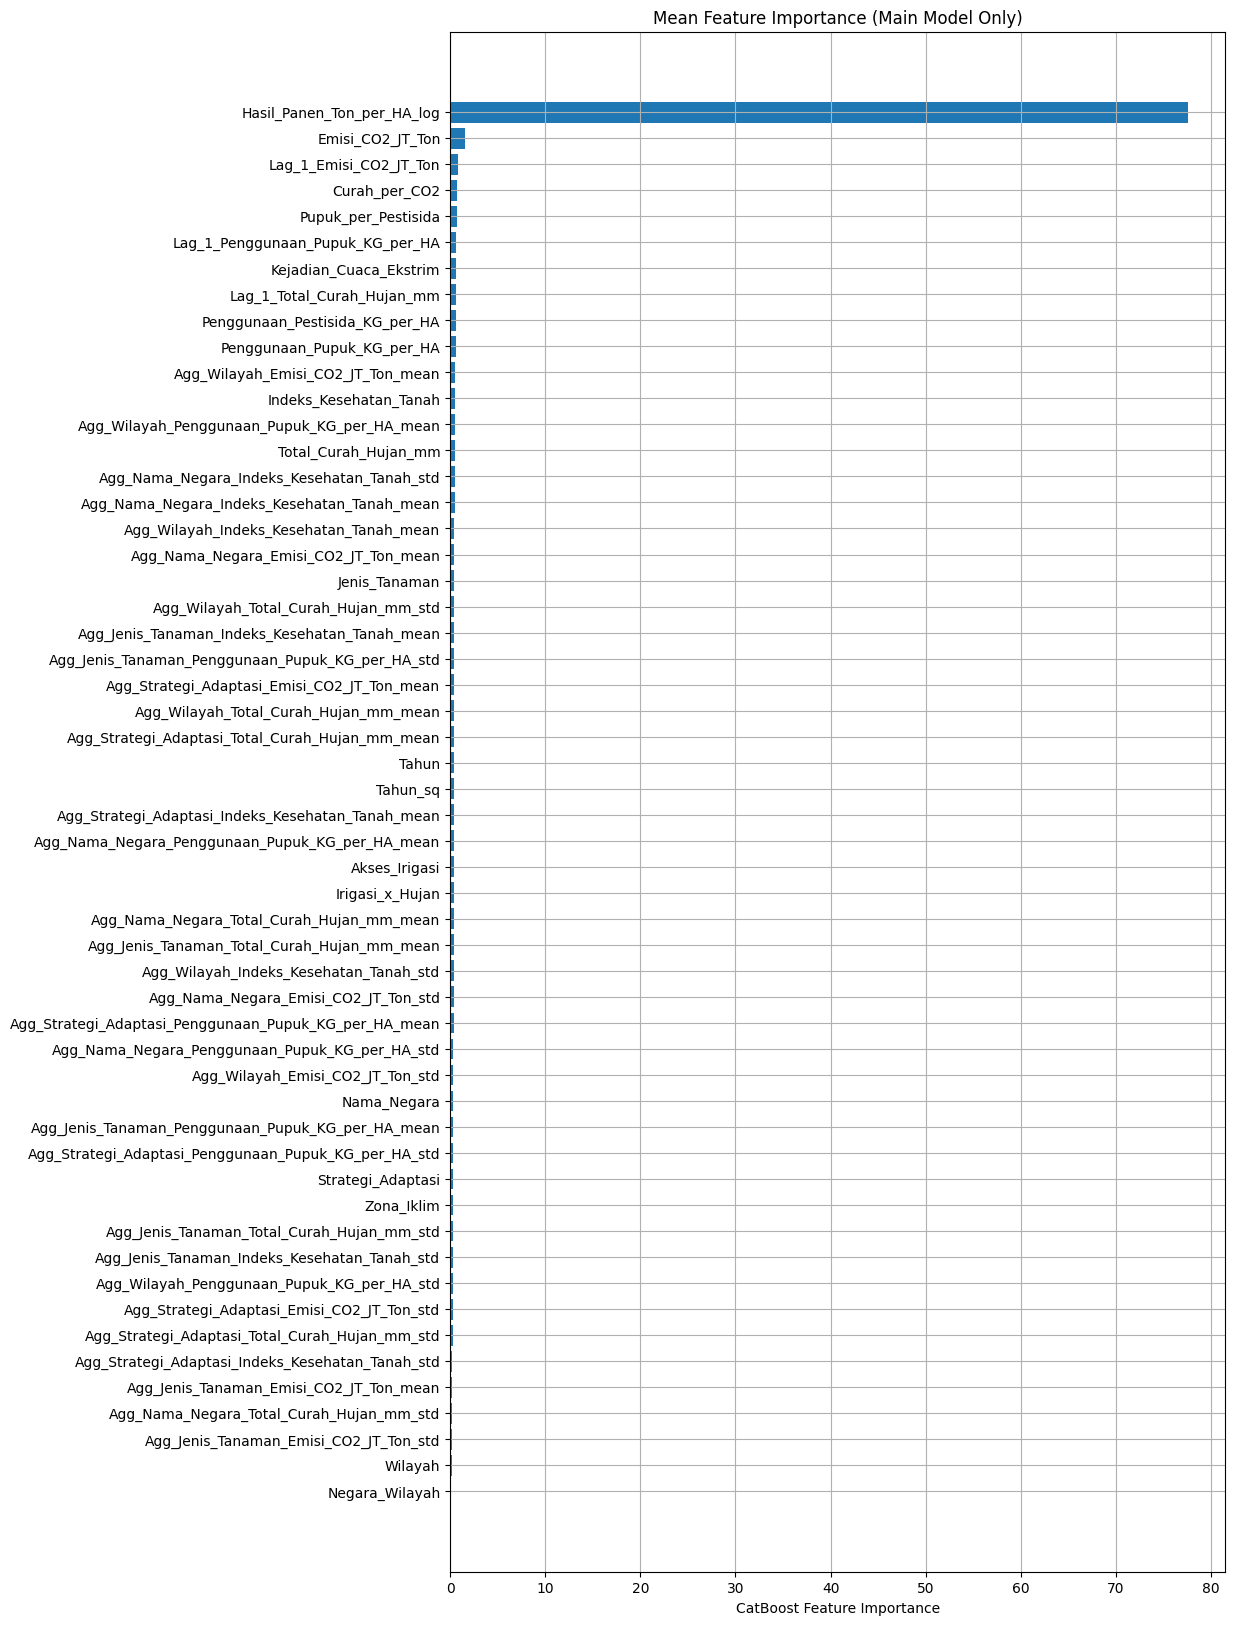

In [55]:
# ==============================
# Cell 12: (UBAH) OOF Score (Blending Adaptif) & Feat Importance (Main Model)
# ==============================
# Pastikan y (true values) dan oof_preds (blended oof) ada
try:
    assert 'y' in locals() and 'oof_preds' in locals()
    # Hitung skor OOF final dari hasil blending adaptif
    oof_score_adapt = mape_eps(y, oof_preds, eps=EPS) # oof_preds sudah di-blend
    print(f"\n==============================")
    print(f"Overall OOF Stabilized MAPE (Adaptive Blend): {oof_score_adapt:.4f}") # Label diubah
    print(f"==============================")

    # Plot OOF Blending Adaptif vs True Values
    plt.figure(figsize=(8, 6))
    plt.scatter(y, oof_preds, alpha=0.2, s=5, label='Adaptive Blend OOF Preds') # Gunakan hasil blend
    plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', label="Ideal")
    plt.xlabel("True Values (Asli)"); plt.ylabel("OOF Predictions (Adaptive Blend)") # Ubah label Y
    plt.title(f"Adaptive Blend OOF vs True Values (MAPE: {oof_score_adapt:.2f})") # Ubah judul
    plt.legend(); plt.grid(True); plt.show()

except NameError as e:
    print(f"Error plotting OOF: Variabel yang dibutuhkan tidak ditemukan ({e}). Jalankan sel sebelumnya.")
except Exception as e:
    print(f"Error saat plotting OOF: {e}")

# Feature Importance masih dari Model Utama (models_main/models)
print("\n--- Feature Importance (dari Model Utama) ---")
try:
    # Asumsi 'models' berisi model CatBoost utama dari Cell 11
    assert 'models' in locals() and 'FEATURES' in locals()
    if models:
        fi_df = pd.DataFrame({'feature': FEATURES})
        if len(models) > 0:
            importances = np.mean([m.get_feature_importance() for m in models], axis=0)
            fi_df['importance'] = importances

            plt.figure(figsize=(10, max(20, len(FEATURES)//3)))
            fi_df_sorted = fi_df.sort_values(by="importance", ascending=True)
            plt.barh(fi_df_sorted["feature"], fi_df_sorted["importance"])
            plt.xlabel("CatBoost Feature Importance")
            plt.title("Mean Feature Importance (Main Model Only)")
            plt.grid(True); plt.show()
        else: print("List model utama kosong.")
    else: print("Model utama (models) tidak terlatih.")
except (NameError, AssertionError) as e:
    print(f"Error plotting Feature Importance: Variabel yang dibutuhkan tidak ditemukan ({e}).")
except Exception as e:
    print(f"Error saat plotting Feature Importance: {e}")

In [56]:
# ==============================
# Cell 13: Submission (Adaptive Blend Predictions)
# ==============================
print(f"Panjang sub: {len(sub)}, Panjang test_preds: {len(test_preds)}")

if len(sub) == len(test_preds):
    sub[TARGET] = test_preds # Gunakan test_preds hasil blending adaptif
    sub.to_csv("submission_adaptive_blend.csv", index=False) # Nama file baru
    print("Submission file (adaptive_blend) created.")
    display(sub.head())
else:
    print(f"ERROR: Panjang prediksi test ({len(test_preds)}) tidak cocok!")

Panjang sub: 2000, Panjang test_preds: 2000
Submission file (adaptive_blend) created.


,ID,Suhu_Rata_Rata_C
0,8000,0.108824
1,8001,18.004360
2,8002,0.144927
3,8003,16.811848
4,8004,0.569387
